In [1]:
%pip install -q ultralytics

In [2]:
from pathlib import Path
from datetime import datetime
from google.colab import files
from IPython.display import display
from PIL import Image

import hashlib
import io
import json
import shutil
import tempfile
import zipfile

import torch
import ultralytics
import yaml

from ultralytics import YOLO

assert torch.cuda.is_available(), (
    "Ative uma GPU nas configurações do ambiente do Colab "
    "e execute esta célula novamente."
)

DEVICE = 0

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
PyTorch: 2.11.0+cu130
Ultralytics: 8.4.203


In [3]:
from google.colab import files

uploaded = files.upload()

arquivos_zip = [
    nome for nome in uploaded
    if nome.lower().endswith(".zip")
]

assert len(arquivos_zip) == 1, "Envie somente o ZIP do dataset."

nome_zip = arquivos_zip[0]

PASTA_EXTRACAO = Path(
    tempfile.mkdtemp(prefix="safracerta_", dir="/content")
)

with zipfile.ZipFile(io.BytesIO(uploaded[nome_zip])) as arquivo:
    # Conferir os caminhos antes de extrair.
    for item in arquivo.infolist():
        destino = (PASTA_EXTRACAO / item.filename).resolve()

        assert destino.is_relative_to(PASTA_EXTRACAO.resolve()), (
            "O ZIP contém um caminho inválido."
        )

    arquivo.extractall(PASTA_EXTRACAO)

DATASET = PASTA_EXTRACAO / "SafraCerta_dataset_lesoes_20"
DATA_YAML = DATASET / "data.yaml"

assert DATA_YAML.exists(), "Não encontrei data.yaml. Confira o ZIP enviado."

# Ajustar a configuração para o local real da extração.
config = yaml.safe_load(DATA_YAML.read_text())
config["path"] = str(DATASET.resolve())

DATA_YAML.write_text(
    yaml.safe_dump(config, allow_unicode=True, sort_keys=False)
)

del uploaded

print("Dataset extraído em:", DATASET)

Saving SafraCerta_dataset_lesoes_20.zip to SafraCerta_dataset_lesoes_20.zip
Dataset extraído em: /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20


In [4]:
contagens_esperadas = {
    "train": 12,
    "val": 4,
    "test": 4,
}

total_caixas = 0
total_negativos = 0
hashes = set()

for conjunto, quantidade in contagens_esperadas.items():
    imagens = sorted((DATASET / "images" / conjunto).glob("*.jpg"))
    rotulos = sorted((DATASET / "labels" / conjunto).glob("*.txt"))

    assert len(imagens) == quantidade
    assert {p.stem for p in imagens} == {p.stem for p in rotulos}

    caixas_conjunto = 0
    negativos_conjunto = 0

    for imagem in imagens:
        assinatura = hashlib.sha256(imagem.read_bytes()).hexdigest()

        assert assinatura not in hashes, "Encontrei uma imagem duplicada."
        hashes.add(assinatura)

        rotulo = DATASET / "labels" / conjunto / f"{imagem.stem}.txt"
        linhas = rotulo.read_text().splitlines()

        if not linhas:
            negativos_conjunto += 1

        for linha in linhas:
            valores = list(map(float, linha.split()))
            assert len(valores) == 5

            classe, cx, cy, largura, altura = valores

            assert classe == 0
            assert 0 < largura <= 1 and 0 < altura <= 1
            assert cx - largura / 2 >= -0.00001
            assert cy - altura / 2 >= -0.00001
            assert cx + largura / 2 <= 1.00001
            assert cy + altura / 2 <= 1.00001

        caixas_conjunto += len(linhas)

    total_caixas += caixas_conjunto
    total_negativos += negativos_conjunto

    print(
        f"{conjunto}: {len(imagens)} imagens, "
        f"{caixas_conjunto} caixas, "
        f"{negativos_conjunto} negativos"
    )

assert total_caixas == 488
assert total_negativos == 10

print("\nDataset conferido!")

train: 12 imagens, 391 caixas, 6 negativos
val: 4 imagens, 81 caixas, 2 negativos
test: 4 imagens, 16 caixas, 2 negativos

Dataset conferido!


In [5]:
NOME_EXECUCAO = datetime.now().strftime("lesoes_%Y%m%d_%H%M%S")

modelo = YOLO("yolo26n.pt")

resultado_treino = modelo.train(
    data=str(DATA_YAML),

    epochs=60,
    patience=15,
    imgsz=640,
    batch=4,
    device=DEVICE,
    workers=2,

    optimizer="AdamW",
    lr0=0.001,

    # Augmentation moderado.
    degrees=10,
    translate=0.05,
    scale=0.15,
    fliplr=0.5,
    flipud=0.0,
    hsv_h=0.01,
    hsv_s=0.3,
    hsv_v=0.2,
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,

    seed=42,
    deterministic=True,
    cache=False,
    plots=True,
    save=True,

    project="/content/SafraCerta_execucoes",
    name=NOME_EXECUCAO,
    exist_ok=False,
)

PASTA_TREINO = Path(modelo.trainer.save_dir)

print("Treinamento concluído!")
print("Resultados:", PASTA_TREINO)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=lesoes_20261105_232255,

In [6]:
BEST = PASTA_TREINO / "weights" / "best.pt"

assert BEST.exists(), "O treinamento ainda não gerou best.pt."

detector = YOLO(str(BEST))

print("Detector carregado!")
print("Arquivo:", BEST)
print("Classes:", detector.names)

Detector carregado!
Arquivo: /content/SafraCerta_execucoes/lesoes_20261105_232255/weights/best.pt
Classes: {0: 'lesao'}


In [7]:
metricas = detector.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=4,
    device=DEVICE,
    workers=2,
    plots=True,
    project=str(PASTA_TREINO),
    name="teste_exploratorio",
)

resumo_metricas = {
    chave: float(valor)
    for chave, valor in metricas.results_dict.items()
}

print(json.dumps(resumo_metricas, indent=2, ensure_ascii=False))

(PASTA_TREINO / "metricas_teste.json").write_text(
    json.dumps(resumo_metricas, indent=2, ensure_ascii=False)
)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1048.7±523.5 MB/s, size: 38.5 KB)
val: Scanning /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/labels/test... 4 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.7Kit/s 0.0s
val: New cache created: /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 11.6it/s 0.1s
                   all          4         16    0.00658      0.312    0.00284    0.00116
Speed: 0.3ms preprocess, 13.5ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /content/SafraCerta_execucoes/lesoes_20261105_232255/teste_exploratorio
{
  "metrics/precision(B)": 0.006578947368421052,
  "metrics/recall(B)": 0.3125,
  "metrics/mAP50(B)": 

207


image 1/4 /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/images/test/tpdd__train_00304.jpg: 448x640 1 lesao, 8.8ms
image 2/4 /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/images/test/tpdd__train_00318.jpg: 448x640 1 lesao, 9.4ms
image 3/4 /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/images/test/tpdd__train_00442.jpg: 448x640 (no detections), 9.7ms
image 4/4 /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/images/test/tpdd__train_00449.jpg: 448x640 2 lesaos, 11.6ms
Speed: 2.3ms preprocess, 9.8ms inference, 1.1ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/SafraCerta_execucoes/lesoes_20261105_232255/predicoes_teste
3 labels saved to /content/SafraCerta_execucoes/lesoes_20261105_232255/predicoes_teste/labels

tpdd__train_00304.jpg: 1 regiões previstas


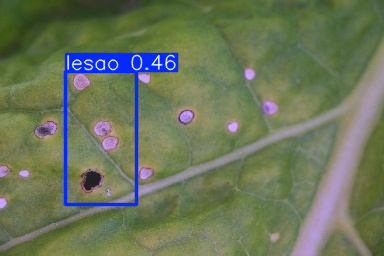


tpdd__train_00318.jpg: 1 regiões previstas


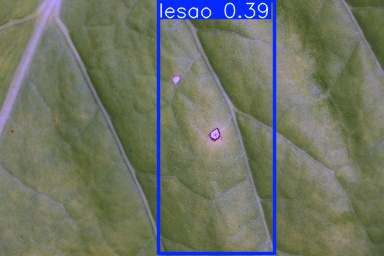


tpdd__train_00442.jpg: 0 regiões previstas


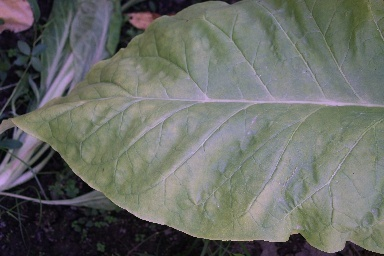


tpdd__train_00449.jpg: 2 regiões previstas


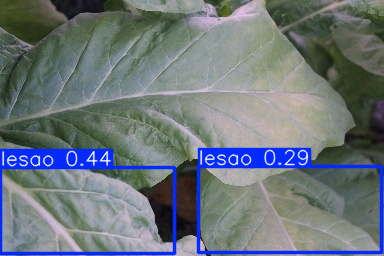

In [8]:
predicoes = detector.predict(
    source=str(DATASET / "images" / "test"),
    imgsz=640,
    conf=0.25,
    device=DEVICE,
    save=True,
    save_txt=True,
    save_conf=True,
    project=str(PASTA_TREINO),
    name="predicoes_teste",
)

for resultado in predicoes:
    quantidade = (
        len(resultado.boxes)
        if resultado.boxes is not None
        else 0
    )

    print(
        f"\n{Path(resultado.path).name}: "
        f"{quantidade} regiões previstas"
    )

    # O plot retorna BGR; converter para RGB.
    imagem_marcada = resultado.plot()[..., ::-1]
    display(Image.fromarray(imagem_marcada))

In [9]:
PASTA_EXPORTACAO = Path("/content") / f"SafraCerta_{NOME_EXECUCAO}"
PASTA_EXPORTACAO.mkdir(parents=True, exist_ok=True)

BEST_EXPORTADO = PASTA_EXPORTACAO / "best_lesoes.pt"
shutil.copy2(BEST, BEST_EXPORTADO)

# Copiar a execução, incluindo gráficos, métricas e previsões.
shutil.copytree(
    PASTA_TREINO,
    PASTA_EXPORTACAO / "execucao",
    dirs_exist_ok=True,
)

# Guardar a configuração e a composição do dataset.
for nome in ["data.yaml", "manifesto.json", "inventario.csv"]:
    shutil.copy2(DATASET / nome, PASTA_EXPORTACAO / nome)

informacoes = {
    "modelo_base": "yolo26n.pt",
    "classe": "lesao",
    "ultralytics": ultralytics.__version__,
    "torch": torch.__version__,
    "gpu": torch.cuda.get_device_name(0),
    "imagens_dataset": 20,
    "anotacoes": "visuais e experimentais",
    "divisao": "provisoria; independencia nao confirmada",
    "metricas_teste": resumo_metricas,
}

(PASTA_EXPORTACAO / "informacoes.json").write_text(
    json.dumps(informacoes, indent=2, ensure_ascii=False)
)

(PASTA_EXPORTACAO / "LEIA-ME.txt").write_text(
    "Detector experimental de regioes da classe lesao.\n"
    "Nao identifica a doenca de cada regiao.\n"
    "Dataset pequeno, anotacoes experimentais e divisao provisoria.\n"
    "As metricas nao comprovam desempenho em fotos novas de campo.\n"
)

ZIP_RESULTADOS = Path(
    shutil.make_archive(
        str(PASTA_EXPORTACAO),
        "zip",
        root_dir=PASTA_EXPORTACAO.parent,
        base_dir=PASTA_EXPORTACAO.name,
    )
)

print("Modelo:", BEST_EXPORTADO)
print("Pacote completo:", ZIP_RESULTADOS)

Modelo: /content/SafraCerta_lesoes_20261105_232255/best_lesoes.pt
Pacote completo: /content/SafraCerta_lesoes_20261105_232255.zip


In [10]:
from google.colab import files

files.download(str(BEST_EXPORTADO))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from google.colab import files

files.download(str(ZIP_RESULTADOS))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


tpdd__train_00314.jpg: 48 caixas
Esquerda: original | Direita: anotações do treinamento


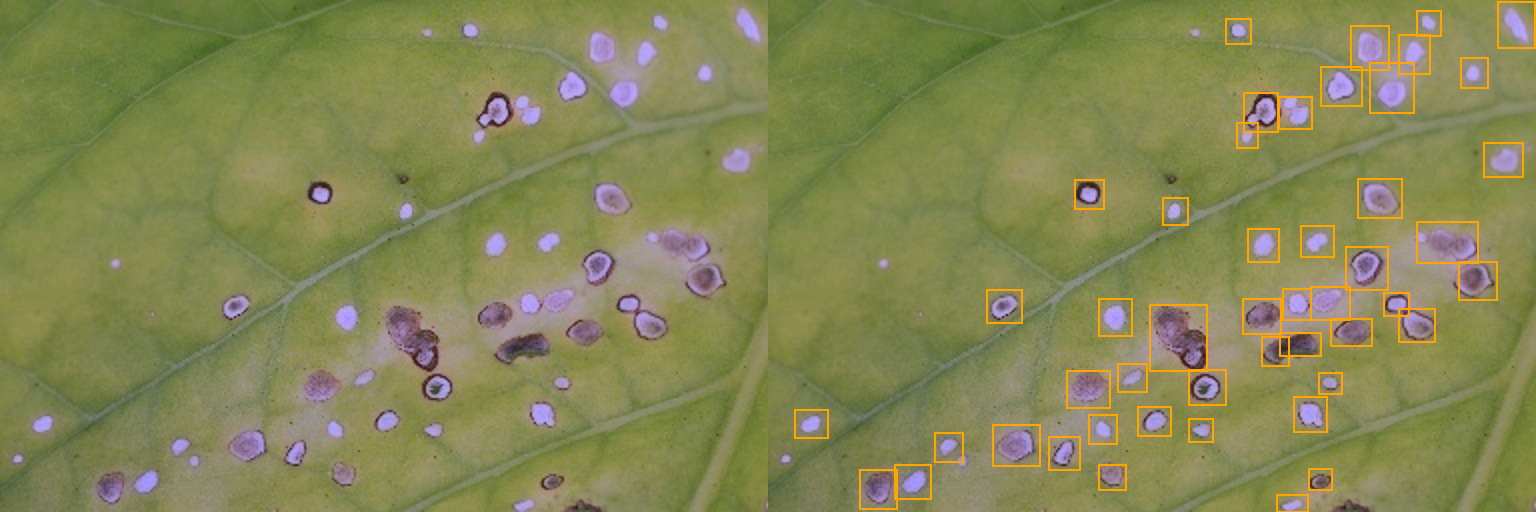


tpdd__train_00422.jpg: 0 caixas
Esquerda: original | Direita: anotações do treinamento


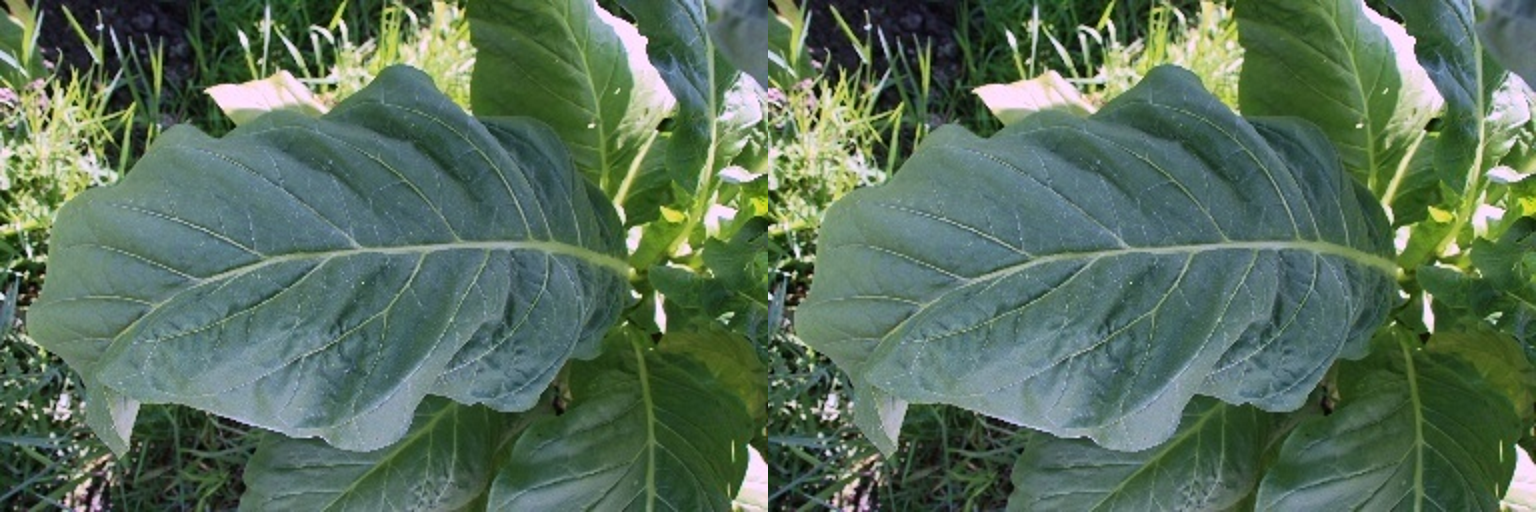

In [12]:
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display

assert "DATASET" in globals(), (
    "Execute novamente as células 2, 3 e 4 para carregar o dataset."
)

# Uma imagem anotada e uma imagem negativa do treino.
exemplos = [
    "tpdd__train_00314.jpg",
    "tpdd__train_00422.jpg",
]

for nome in exemplos:
    caminho_imagem = DATASET / "images" / "train" / nome
    caminho_rotulo = (
        DATASET / "labels" / "train" / f"{Path(nome).stem}.txt"
    )

    original = Image.open(caminho_imagem).convert("RGB")
    original = original.resize((768, 512))

    marcada = original.copy()
    desenho = ImageDraw.Draw(marcada)

    largura, altura = marcada.size
    linhas = caminho_rotulo.read_text().splitlines()

    for linha in linhas:
        classe, cx, cy, w, h = map(float, linha.split())

        x1 = (cx - w / 2) * largura
        y1 = (cy - h / 2) * altura
        x2 = (cx + w / 2) * largura
        y2 = (cy + h / 2) * altura

        desenho.rectangle(
            [x1, y1, x2, y2],
            outline="orange",
            width=2,
        )

    painel = Image.new("RGB", (1536, 512), "white")
    painel.paste(original, (0, 0))
    painel.paste(marcada, (768, 0))

    print(f"\n{nome}: {len(linhas)} caixas")
    print("Esquerda: original | Direita: anotações do treinamento")
    display(painel)

In [13]:
from pathlib import Path
from datetime import datetime
from ultralytics import YOLO

import shutil
import tempfile
import torch
import yaml

assert "DATASET" in globals(), "Carregue o dataset primeiro."
assert torch.cuda.is_available(), "Ative a GPU do Colab."

CONTROLE = Path(
    tempfile.mkdtemp(prefix="safracerta_controle_", dir="/content")
)

(CONTROLE / "images").mkdir()
(CONTROLE / "labels").mkdir()

# Somente imagens do conjunto de treinamento.
nomes = [
    "tpdd__train_00302.jpg",
    "tpdd__train_00314.jpg",
    "tpdd__train_00422.jpg",
    "tpdd__train_00423.jpg",
]

for nome in nomes:
    rotulo = f"{Path(nome).stem}.txt"

    shutil.copy2(
        DATASET / "images" / "train" / nome,
        CONTROLE / "images" / nome,
    )

    shutil.copy2(
        DATASET / "labels" / "train" / rotulo,
        CONTROLE / "labels" / rotulo,
    )

config_controle = {
    "path": str(CONTROLE),
    "train": "images",
    # Repetição intencional: diagnóstico de memorização.
    "val": "images",
    "names": {0: "lesao"},
}

YAML_CONTROLE = CONTROLE / "data.yaml"

YAML_CONTROLE.write_text(
    yaml.safe_dump(config_controle, sort_keys=False)
)

modelo_controle = YOLO("yolo26n.pt")

resultado_controle = modelo_controle.train(
    data=str(YAML_CONTROLE),
    epochs=200,
    patience=0,

    imgsz=640,
    batch=4,
    nbs=4,
    device=0,
    workers=2,

    optimizer="AdamW",
    lr0=0.001,
    lrf=0.1,
    warmup_epochs=0,
    weight_decay=0.0,

    # Sem augmentation neste diagnóstico.
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    degrees=0.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,
    fliplr=0.0,
    flipud=0.0,
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,
    close_mosaic=0,

    amp=False,
    seed=42,
    deterministic=True,
    plots=True,

    project="/content/SafraCerta_controle",
    name=datetime.now().strftime("memorizacao_%Y%m%d_%H%M%S"),
)

PASTA_CONTROLE = Path(modelo_controle.trainer.save_dir)
BEST_CONTROLE = PASTA_CONTROLE / "weights" / "best.pt"

print("\nTeste controlado concluído!")
print("Modelo de diagnóstico:", BEST_CONTROLE)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/safracerta_controle_bj7nb761/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=memorizacao_20261105_233946, nbs=4, nms=Non


image 1/4 /content/safracerta_controle_bj7nb761/images/tpdd__train_00302.jpg: 448x640 92 lesaos, 8.9ms
image 2/4 /content/safracerta_controle_bj7nb761/images/tpdd__train_00314.jpg: 448x640 48 lesaos, 11.5ms
image 3/4 /content/safracerta_controle_bj7nb761/images/tpdd__train_00422.jpg: 448x640 (no detections), 10.2ms
image 4/4 /content/safracerta_controle_bj7nb761/images/tpdd__train_00423.jpg: 448x640 (no detections), 8.9ms
Speed: 1.8ms preprocess, 9.9ms inference, 0.9ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/SafraCerta_controle/memorizacao_20261105_233946/previsoes_memorizacao

tpdd__train_00302.jpg: 92 regiões previstas


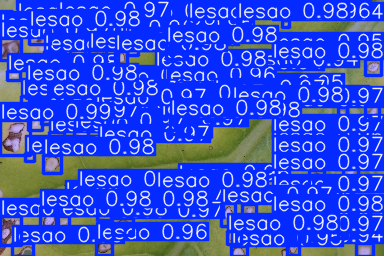


tpdd__train_00314.jpg: 48 regiões previstas


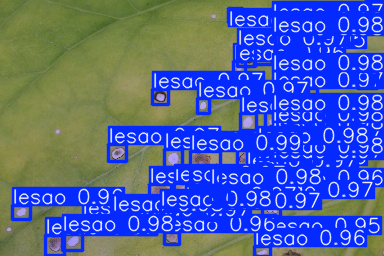


tpdd__train_00422.jpg: 0 regiões previstas


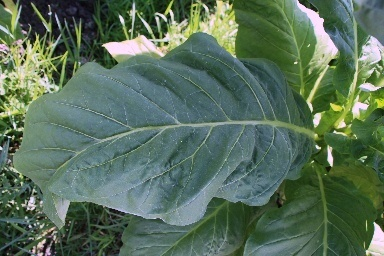


tpdd__train_00423.jpg: 0 regiões previstas


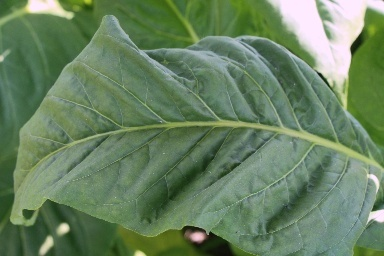

In [14]:
from PIL import Image
from IPython.display import display

detector_controle = YOLO(str(BEST_CONTROLE))

previsoes_controle = detector_controle.predict(
    source=str(CONTROLE / "images"),
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project=str(PASTA_CONTROLE),
    name="previsoes_memorizacao",
)

for resultado in previsoes_controle:
    print(
        f"\n{Path(resultado.path).name}: "
        f"{len(resultado.boxes)} regiões previstas"
    )

    display(Image.fromarray(resultado.plot()[..., ::-1]))

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1427.6±471.6 MB/s, size: 38.9 KB)
val: Scanning /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/labels/val.cache... 4 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 18.1it/s 0.1s
                   all          4         81      0.824      0.693      0.648      0.202
Speed: 0.3ms preprocess, 6.0ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /content/SafraCerta_controle/memorizacao_20261105_233946/validacao_fora_controle

Métricas nas imagens fora do controle:
metrics/precision(B): 0.8238
metrics/recall(B): 0.6925
metrics/mAP50(B): 0.6485
metrics/mAP50-95(B): 0.2024
fitness: 0.2024

image 1/4 /content/safrac

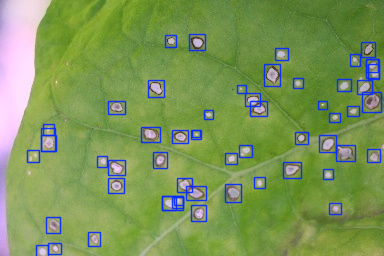


tpdd__train_00299.jpg: 32 regiões previstas


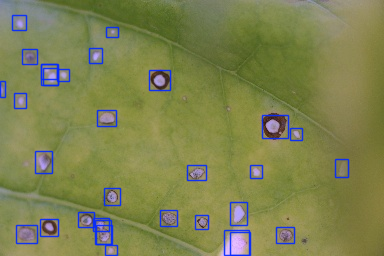


tpdd__train_00431.jpg: 2 regiões previstas


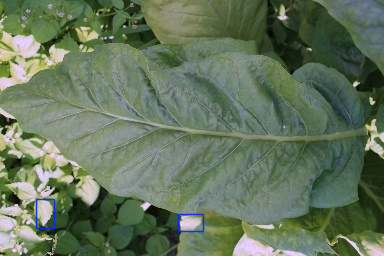


tpdd__train_00435.jpg: 0 regiões previstas


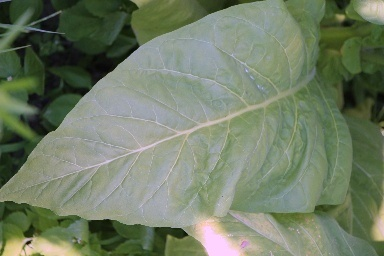

In [15]:
# Avaliar fora das quatro imagens memorizadas.
metricas_fora_controle = detector_controle.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    plots=True,
    project=str(PASTA_CONTROLE),
    name="validacao_fora_controle",
)

print("\nMétricas nas imagens fora do controle:")
for nome, valor in metricas_fora_controle.results_dict.items():
    print(f"{nome}: {float(valor):.4f}")

# Mostrar previsões nessas imagens.
previsoes_validacao = detector_controle.predict(
    source=str(DATASET / "images" / "val"),
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project=str(PASTA_CONTROLE),
    name="previsoes_validacao",
)

for resultado in previsoes_validacao:
    print(
        f"\n{Path(resultado.path).name}: "
        f"{len(resultado.boxes)} regiões previstas"
    )

    imagem = resultado.plot(
        labels=False,
        conf=False,
        line_width=1,
    )

    display(Image.fromarray(imagem[..., ::-1]))

In [16]:
from pathlib import Path
from datetime import datetime
from ultralytics import YOLO
import torch

assert "DATA_YAML" in globals(), "Carregue o dataset primeiro."
assert Path(DATA_YAML).exists(), "Não encontrei o data.yaml."
assert torch.cuda.is_available(), "Ative a GPU do Colab."

# Começar novamente com os pesos pré-treinados.
modelo_ajustado = YOLO("yolo26n.pt")

resultado_ajustado = modelo_ajustado.train(
    data=str(DATA_YAML),

    epochs=200,
    patience=50,
    imgsz=640,

    # Atualização dos pesos a cada lote.
    batch=4,
    nbs=4,
    device=0,
    workers=2,

    optimizer="AdamW",
    lr0=0.001,
    lrf=0.1,
    warmup_epochs=0,
    weight_decay=0.0005,

    # Augmentation moderado, somente no treinamento.
    hsv_h=0.01,
    hsv_s=0.15,
    hsv_v=0.15,
    degrees=5,
    translate=0.02,
    scale=0.1,
    fliplr=0.5,
    flipud=0.0,
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,
    close_mosaic=0,

    amp=False,
    seed=42,
    deterministic=True,
    cache=False,
    plots=True,
    save=True,

    # Acompanhar o aprendizado nas imagens de validação.
    val=True,
    split="val",

    project="/content/SafraCerta_treino_ajustado",
    name=datetime.now().strftime("lesoes_%Y%m%d_%H%M%S"),
    exist_ok=False,
)

PASTA_AJUSTADO = Path(modelo_ajustado.trainer.save_dir)
BEST_AJUSTADO = PASTA_AJUSTADO / "weights" / "best.pt"

assert BEST_AJUSTADO.exists(), "Não encontrei o novo best.pt."

print("\nTreinamento concluído!")
print("Novo modelo:", BEST_AJUSTADO)

print("\nMétricas de validação retornadas:")
for nome, valor in resultado_ajustado.results_dict.items():
    print(f"{nome}: {float(valor):.4f}")

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/data.yaml, degrees=5, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.15, hsv_v=0.15, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=lesoes_20261105_235339


image 1/4 /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/images/val/tpdd__train_00294.jpg: 448x640 73 lesaos, 9.1ms
image 2/4 /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/images/val/tpdd__train_00299.jpg: 448x640 45 lesaos, 10.1ms
image 3/4 /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/images/val/tpdd__train_00431.jpg: 448x640 72 lesaos, 9.5ms
image 4/4 /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/images/val/tpdd__train_00435.jpg: 448x640 1 lesao, 18.1ms
Speed: 1.9ms preprocess, 11.7ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/SafraCerta_treino_ajustado/lesoes_20261105_235339/previsoes_validacao

tpdd__train_00294.jpg: 73 regiões previstas


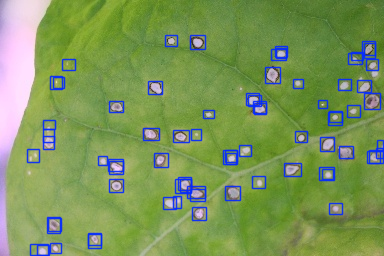


tpdd__train_00299.jpg: 45 regiões previstas


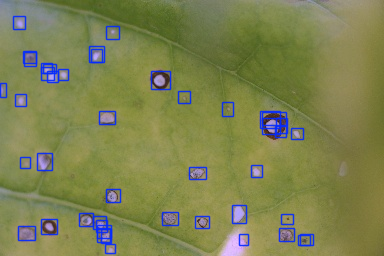


tpdd__train_00431.jpg: 72 regiões previstas


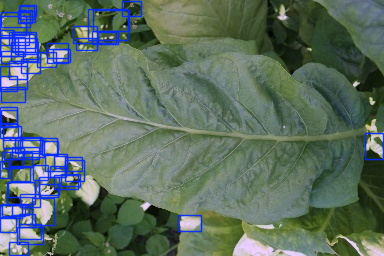


tpdd__train_00435.jpg: 1 regiões previstas


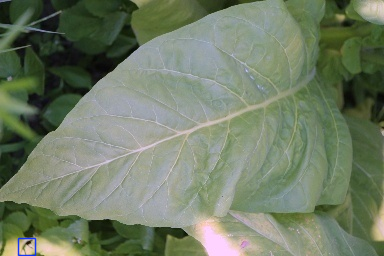

In [17]:
from PIL import Image
from IPython.display import display

detector_ajustado = YOLO(str(BEST_AJUSTADO))

previsoes_ajustadas = detector_ajustado.predict(
    source=str(DATASET / "images" / "val"),
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project=str(PASTA_AJUSTADO),
    name="previsoes_validacao",
)

for resultado in previsoes_ajustadas:
    print(
        f"\n{Path(resultado.path).name}: "
        f"{len(resultado.boxes)} regiões previstas"
    )

    imagem = resultado.plot(
        labels=False,
        conf=False,
        line_width=1,
    )

    display(Image.fromarray(imagem[..., ::-1]))

In [19]:
from pathlib import Path
import pandas as pd

assert "detector_ajustado" in globals(), (
    "Execute primeiro a célula que carrega o detector ajustado."
)

# Fazer as previsões uma vez, no menor limite.
resultados_limites = detector_ajustado.predict(
    source=str(DATASET / "images" / "val"),
    imgsz=640,
    conf=0.25,
    classes=[0],
    device=0,
    save=False,
    verbose=False,
)

# Calcular a sobreposição entre duas caixas.
def calcular_iou(a, b):
    inter_largura = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    inter_altura = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    intersecao = inter_largura * inter_altura

    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])

    uniao = area_a + area_b - intersecao
    return intersecao / uniao if uniao > 0 else 0.0


# Carregar as caixas anotadas e as previstas.
dados_validacao = []

for resultado in resultados_limites:
    altura, largura = resultado.orig_shape

    rotulo = (
        DATASET / "labels" / "val"
        / f"{Path(resultado.path).stem}.txt"
    )

    caixas_anotadas = []

    for linha in rotulo.read_text().splitlines():
        if not linha.strip():
            continue

        classe, cx, cy, w, h = map(float, linha.split())

        caixas_anotadas.append([
            (cx - w / 2) * largura,
            (cy - h / 2) * altura,
            (cx + w / 2) * largura,
            (cy + h / 2) * altura,
        ])

    caixas_previstas = [
        (caixa, confianca)
        for caixa, confianca in zip(
            resultado.boxes.xyxy.cpu().tolist(),
            resultado.boxes.conf.cpu().tolist(),
        )
    ]

    dados_validacao.append({
        "anotadas": caixas_anotadas,
        "previstas": caixas_previstas,
    })


# Cada previsão pode corresponder a apenas uma anotação.
# Considerar acerto quando a sobreposição IoU for >= 0.50.
comparacao = []

for limite in [0.60, 0.70, 0.80, 0.90, 0.95]:
    acertos = 0
    falsos_positivos = 0
    nao_encontradas = 0
    falsos_em_negativas = 0

    for imagem in dados_validacao:
        anotadas = imagem["anotadas"]

        previstas = sorted(
            [
                (caixa, confianca)
                for caixa, confianca in imagem["previstas"]
                if confianca >= limite
            ],
            key=lambda item: item[1],
            reverse=True,
        )

        utilizadas = set()

        for caixa, confianca in previstas:
            candidatas = [
                (calcular_iou(caixa, anotada), indice)
                for indice, anotada in enumerate(anotadas)
                if indice not in utilizadas
            ]

            melhor_iou, indice = max(
                candidatas,
                default=(0.0, -1),
            )

            if melhor_iou >= 0.50:
                acertos += 1
                utilizadas.add(indice)
            else:
                falsos_positivos += 1

                if not anotadas:
                    falsos_em_negativas += 1

        nao_encontradas += len(anotadas) - len(utilizadas)

    precisao = acertos / max(acertos + falsos_positivos, 1)
    recall = acertos / max(acertos + nao_encontradas, 1)

    comparacao.append({
        "Confiança mínima": limite,
        "Acertos": acertos,
        "Marcações falsas": falsos_positivos,
        "Não encontradas": nao_encontradas,
        "Precisão (%)": round(precisao * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "Falsas nas negativas": falsos_em_negativas,
    })

tabela_confianca = pd.DataFrame(comparacao)
display(tabela_confianca)

tabela_confianca.to_csv(
    PASTA_AJUSTADO / "comparacao_confianca_validacao.csv",
    index=False,
)

print("Comparação concluída, sem novo treinamento.")

,Confiança mínima,Acertos,Marcações falsas,Não encontradas,Precisão (%),Recall (%),Falsas nas negativas
0,0.60,60,40,21,60.00,74.07,16
1,0.70,60,29,21,67.42,74.07,9
2,0.80,55,17,26,76.39,67.90,4
3,0.90,42,1,39,97.67,51.85,0
4,0.95,6,0,75,100.00,7.41,0


Comparação concluída, sem novo treinamento.



image 1/4 /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/images/test/tpdd__train_00304.jpg: 448x640 11 lesaos, 36.2ms
image 2/4 /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/images/test/tpdd__train_00318.jpg: 448x640 3 lesaos, 27.0ms
image 3/4 /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/images/test/tpdd__train_00442.jpg: 448x640 (no detections), 31.6ms
image 4/4 /content/safracerta_md_3c8x1/SafraCerta_dataset_lesoes_20/images/test/tpdd__train_00449.jpg: 448x640 (no detections), 30.2ms
Speed: 4.5ms preprocess, 31.2ms inference, 4.2ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/SafraCerta_treino_ajustado/lesoes_20261105_235339/teste_confianca_080
2 labels saved to /content/SafraCerta_treino_ajustado/lesoes_20261105_235339/teste_confianca_080/labels

tpdd__train_00304.jpg: 11 regiões previstas


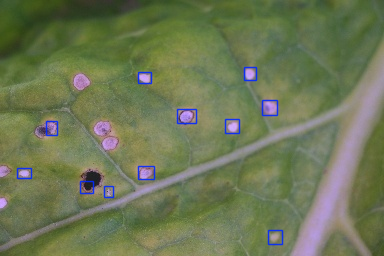


tpdd__train_00318.jpg: 3 regiões previstas


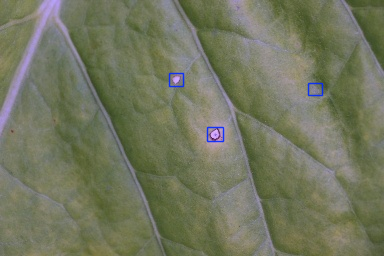


tpdd__train_00442.jpg: 0 regiões previstas


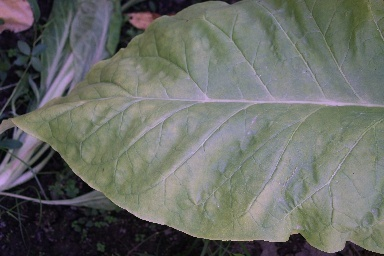


tpdd__train_00449.jpg: 0 regiões previstas


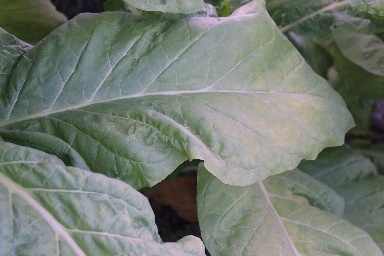

In [20]:
from pathlib import Path
from PIL import Image
from IPython.display import display

CONFIANCA_ESCOLHIDA = 0.80

resultados_teste_final = detector_ajustado.predict(
    source=str(DATASET / "images" / "test"),
    imgsz=640,
    conf=CONFIANCA_ESCOLHIDA,
    device=0,
    save=True,
    save_txt=True,
    save_conf=True,
    show_labels=False,
    show_conf=False,
    line_width=1,
    project=str(PASTA_AJUSTADO),
    name="teste_confianca_080",
)

for resultado in resultados_teste_final:
    print(
        f"\n{Path(resultado.path).name}: "
        f"{len(resultado.boxes)} regiões previstas"
    )

    imagem = resultado.plot(
        labels=False,
        conf=False,
        line_width=1,
    )

    display(Image.fromarray(imagem[..., ::-1]))

In [21]:
from pathlib import Path
import pandas as pd
import json

linhas_teste = []

for resultado in resultados_teste_final:
    altura, largura = resultado.orig_shape
    nome = Path(resultado.path).name

    rotulo = (
        DATASET / "labels" / "test"
        / f"{Path(nome).stem}.txt"
    )

    anotadas = []

    for linha in rotulo.read_text().splitlines():
        if not linha.strip():
            continue

        classe, cx, cy, w, h = map(float, linha.split())

        anotadas.append([
            (cx - w / 2) * largura,
            (cy - h / 2) * altura,
            (cx + w / 2) * largura,
            (cy + h / 2) * altura,
        ])

    previstas = sorted(
        zip(
            resultado.boxes.xyxy.cpu().tolist(),
            resultado.boxes.conf.cpu().tolist(),
        ),
        key=lambda item: item[1],
        reverse=True,
    )

    utilizadas = set()
    acertos = 0
    falsas = 0

    for caixa, confianca in previstas:
        candidatas = [
            (calcular_iou(caixa, anotada), indice)
            for indice, anotada in enumerate(anotadas)
            if indice not in utilizadas
        ]

        melhor_iou, indice = max(
            candidatas,
            default=(0.0, -1),
        )

        if melhor_iou >= 0.50:
            acertos += 1
            utilizadas.add(indice)
        else:
            falsas += 1

    linhas_teste.append({
        "Imagem": nome,
        "Anotadas": len(anotadas),
        "Previstas": len(previstas),
        "Acertos": acertos,
        "Marcações falsas": falsas,
        "Não encontradas": len(anotadas) - len(utilizadas),
    })

tabela_teste = pd.DataFrame(linhas_teste)
display(tabela_teste)

tp = int(tabela_teste["Acertos"].sum())
fp = int(tabela_teste["Marcações falsas"].sum())
fn = int(tabela_teste["Não encontradas"].sum())

resumo_teste_final = {
    "confianca": float(CONFIANCA_ESCOLHIDA),
    "iou_minimo": 0.50,
    "acertos": tp,
    "marcacoes_falsas": fp,
    "nao_encontradas": fn,
    "precisao_percentual": round(100 * tp / max(tp + fp, 1), 2),
    "recall_percentual": round(100 * tp / max(tp + fn, 1), 2),
}

print(json.dumps(resumo_teste_final, indent=2, ensure_ascii=False))

tabela_teste.to_csv(
    PASTA_AJUSTADO / "contagem_teste_conf080.csv",
    index=False,
)

(PASTA_AJUSTADO / "resumo_teste_conf080.json").write_text(
    json.dumps(resumo_teste_final, indent=2, ensure_ascii=False)
)

,Imagem,Anotadas,Previstas,Acertos,Marcações falsas,Não encontradas
0,tpdd__train_00304.jpg,14,11,5,6,9
1,tpdd__train_00318.jpg,2,3,2,1,0
2,tpdd__train_00442.jpg,0,0,0,0,0
3,tpdd__train_00449.jpg,0,0,0,0,0


{
  "confianca": 0.8,
  "iou_minimo": 0.5,
  "acertos": 7,
  "marcacoes_falsas": 7,
  "nao_encontradas": 9,
  "precisao_percentual": 50.0,
  "recall_percentual": 43.75
}


169

In [22]:
from pathlib import Path
from datetime import datetime

import hashlib
import json
import platform
import shutil
import torch
import ultralytics
import yaml

# Conferir se estamos usando a execução ajustada.
assert Path(BEST_AJUSTADO).exists(), "Não encontrei o modelo ajustado."
assert Path(PASTA_AJUSTADO).exists(), "Não encontrei os resultados."
assert "resumo_teste_final" in globals(), "Execute a contagem do teste primeiro."

assert abs(resumo_teste_final["confianca"] - 0.80) < 0.000001

nome_pacote = datetime.now().strftime(
    "SafraCerta_piloto_lesoes_%Y%m%d_%H%M%S"
)

EXPORTACAO_FINAL = Path("/content") / nome_pacote
(EXPORTACAO_FINAL / "modelos").mkdir(parents=True)

# Modelo principal deste piloto.
MODELO_FINAL = (
    EXPORTACAO_FINAL / "modelos" / "best_lesoes_experimental.pt"
)

shutil.copy2(BEST_AJUSTADO, MODELO_FINAL)

# Treinamento ajustado, gráficos, previsões e tabelas.
shutil.copytree(
    PASTA_AJUSTADO,
    EXPORTACAO_FINAL / "execucao_ajustada",
)

# Preservar também as imagens e os rótulos utilizados.
shutil.copytree(
    DATASET,
    EXPORTACAO_FINAL / "dataset",
)

# Ajustar o caminho da cópia do dataset.
yaml_exportado = EXPORTACAO_FINAL / "dataset" / "data.yaml"
config_dataset = yaml.safe_load(yaml_exportado.read_text())
config_dataset["path"] = str(EXPORTACAO_FINAL / "dataset")

yaml_exportado.write_text(
    yaml.safe_dump(
        config_dataset,
        allow_unicode=True,
        sort_keys=False,
    )
)

config_inferencia = {
    "modelo": "modelos/best_lesoes_experimental.pt",
    "classe": "lesao",
    "conf": 0.80,
    "imgsz": 640,
    "status": "piloto_academico_experimental",
}

(EXPORTACAO_FINAL / "config_inferencia.json").write_text(
    json.dumps(config_inferencia, indent=2, ensure_ascii=False)
)

(EXPORTACAO_FINAL / "resultado_teste.json").write_text(
    json.dumps(resumo_teste_final, indent=2, ensure_ascii=False)
)

ambiente = {
    "python": platform.python_version(),
    "ultralytics": ultralytics.__version__,
    "torch": torch.__version__,
    "sha256_modelo": hashlib.sha256(
        MODELO_FINAL.read_bytes()
    ).hexdigest(),
}

(EXPORTACAO_FINAL / "ambiente.json").write_text(
    json.dumps(ambiente, indent=2, ensure_ascii=False)
)

(EXPORTACAO_FINAL / "LEIA-ME.txt").write_text(
    "SafraCerta — piloto academico de deteccao de lesoes\n\n"
    "Modelo principal: modelos/best_lesoes_experimental.pt\n"
    "Classe unica: lesao\n"
    "Confianca escolhida na validacao: 0.80\n"
    "Tamanho de inferencia: 640\n\n"
    "O modelo localiza regioes visuais; nao identifica a doenca "
    "de cada mancha.\n\n"
    "Teste exploratorio: 4 fotos, com anotacoes experimentais.\n"
    "Os resultados completos estao em resultado_teste.json.\n"
    "A contagem utiliza correspondencia unica e IoU minimo de 0.50; "
    "nao e calculo de mAP.\n\n"
    "Limitacoes: dataset pequeno, baixa resolucao, anotacoes "
    "nao validadas por especialista e independencia entre folhas "
    "nao confirmada. O teste ja foi inspecionado em experimentos "
    "anteriores e nao representa uma avaliacao externa independente.\n"
    "Este piloto ainda nao demonstra confiabilidade para uso em campo.\n\n"
    "Para reutilizar o dataset em outro diretorio, ajustar o campo "
    "path do arquivo dataset/data.yaml.\n",
    encoding="utf-8",
)

ZIP_FINAL = Path(
    shutil.make_archive(
        str(EXPORTACAO_FINAL),
        "zip",
        root_dir=EXPORTACAO_FINAL.parent,
        base_dir=EXPORTACAO_FINAL.name,
    )
)

print("Pacote preparado:", ZIP_FINAL)
print("Modelo incluído:", MODELO_FINAL.name)
print("Resultados do teste:")
print(json.dumps(resumo_teste_final, indent=2, ensure_ascii=False))

Pacote preparado: /content/SafraCerta_piloto_lesoes_20261106_001012.zip
Modelo incluído: best_lesoes_experimental.pt
Resultados do teste:
{
  "confianca": 0.8,
  "iou_minimo": 0.5,
  "acertos": 7,
  "marcacoes_falsas": 7,
  "nao_encontradas": 9,
  "precisao_percentual": 50.0,
  "recall_percentual": 43.75
}


In [23]:
from google.colab import files

files.download(str(ZIP_FINAL))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>